PART 1

Uploading CSV file

In [3]:
from google.colab import files
uploaded = files.upload()


Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


Loading the dataset

In [4]:
import pandas as pd

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Number of rows: 7043
Number of columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Understanding the columns

In [5]:
print(df.columns.tolist())
print("\nDataset information:")
df.info()

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 no

Checking data quality

In [6]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nChurn distribution:")
print(df["Churn"].value_counts())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64


PART 2: SQL and data cleaning

Identifying data quality issues

In [7]:
# Check blank values in the dataset
print("Blank values by column:")
print(df.isin([""]).sum().sort_values(ascending=False).head(10))

# Check the data types
print("\nData types:")
print(df.dtypes)

Blank values by column:
customerID         0
gender             0
SeniorCitizen      0
Partner            0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
OnlineSecurity     0
dtype: int64

Data types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


Cleaning the data

In [8]:
import numpy as np

# Create a working copy so the original stays unchanged
df_clean = df.copy()

# Convert TotalCharges to numeric; invalid blanks become missing values
df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing values before cleaning:")
print(df_clean.isnull().sum().sort_values(ascending=False).head(10))

# Remove duplicate customer records, if any
df_clean = df_clean.drop_duplicates(subset=["customerID"])

# Remove records missing the target or essential numeric fields
df_clean = df_clean.dropna(
    subset=["Churn", "tenure", "MonthlyCharges", "TotalCharges"]
)

print("\nCleaned dataset shape:", df_clean.shape)
print("Remaining duplicate customer IDs:",
      df_clean["customerID"].duplicated().sum())


Missing values before cleaning:
TotalCharges      11
gender             0
SeniorCitizen      0
Partner            0
customerID         0
Dependents         0
tenure             0
MultipleLines      0
PhoneService       0
OnlineSecurity     0
dtype: int64

Cleaned dataset shape: (7032, 21)
Remaining duplicate customer IDs: 0


Loading the cleaned data into SQL

In [9]:
import sqlite3

# Create an in-memory SQL database
conn = sqlite3.connect(":memory:")

# Load the cleaned DataFrame into a SQL table
df_clean.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False
)

print("Customers table created successfully!")

Customers table created successfully!


In [10]:
query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers;
"""

pd.read_sql_query(query, conn)

,total_customers,churned_customers,churn_rate_percent
0,7032,1869,26.58


Investigating churn by contract type

In [11]:
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate_percent
FROM customers
GROUP BY Contract
ORDER BY churn_rate_percent DESC;
"""

pd.read_sql_query(query, conn)

,Contract,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1472,166,11.28
2,Two year,1685,48,2.85


PART 3: Exploratory data analysis and statistical testing

Calculating churn rates by contract type

In [14]:
import pandas as pd

contract_summary = (
    df_clean.groupby("Contract")
    .agg(
        total_customers=("customerID", "count"),
        churned_customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

contract_summary["churn_rate_percent"] = (
    contract_summary["churned_customers"]
    / contract_summary["total_customers"] * 100
).round(2)

contract_summary.sort_values(
    "churn_rate_percent", ascending=False
)


,Contract,total_customers,churned_customers,churn_rate_percent
0,Month-to-month,3875,1655,42.71
1,One year,1472,166,11.28
2,Two year,1685,48,2.85


Visualizing your findings

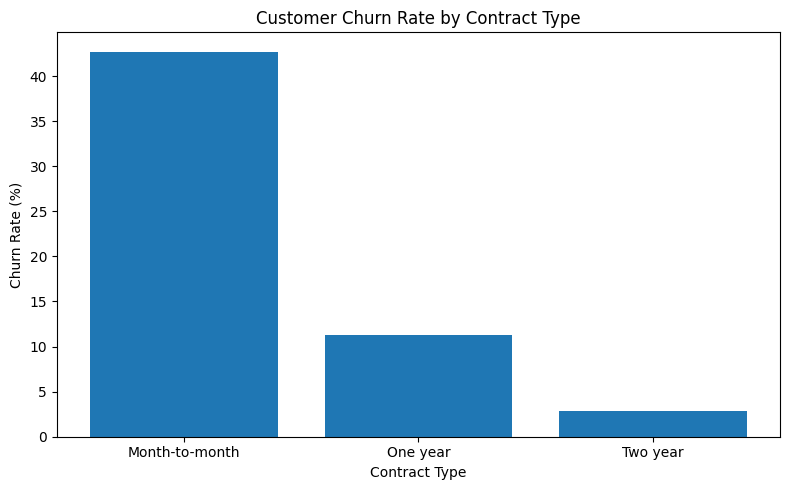

In [15]:
import matplotlib.pyplot as plt

contract_summary = contract_summary.sort_values(
    "churn_rate_percent", ascending=False
)

plt.figure(figsize=(8, 5))
plt.bar(
    contract_summary["Contract"],
    contract_summary["churn_rate_percent"]
)
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()

Investigating customer tenure

  tenure_group  total_customers  churned_customers  churn_rate_percent
0         0-12             2175               1037               47.68
1        13-24             1024                294               28.71
2        25-48             1594                325               20.39
3        49-60              832                120               14.42
4        61-72             1407                 93                6.61


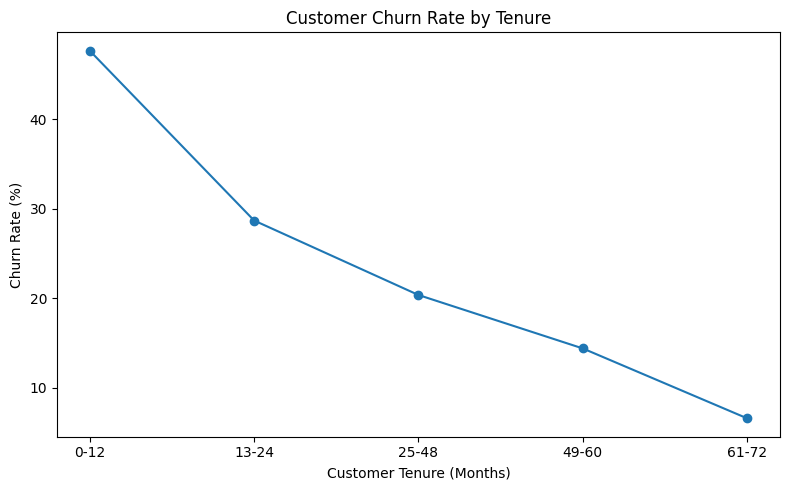

In [16]:
df_clean["tenure_group"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"]
)

tenure_summary = (
    df_clean.groupby("tenure_group", observed=True)
    .agg(
        total_customers=("customerID", "count"),
        churned_customers=("Churn", lambda x: (x == "Yes").sum())
    )
    .reset_index()
)

tenure_summary["churn_rate_percent"] = (
    100 * tenure_summary["churned_customers"]
    / tenure_summary["total_customers"]
).round(2)

print(tenure_summary)

plt.figure(figsize=(8, 5))
plt.plot(
    tenure_summary["tenure_group"].astype(str),
    tenure_summary["churn_rate_percent"],
    marker="o"
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure (Months)")
plt.ylabel("Churn Rate (%)")
plt.tight_layout()
plt.show()


Performing a statistical significance test

In [17]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df_clean["Contract"],
    df_clean["Churn"]
)

chi2, p_value, degrees_of_freedom, expected = (
    chi2_contingency(contingency_table)
)

print("Observed counts:")
print(contingency_table)

print("\nChi-square statistic:", round(chi2, 2))
print("Degrees of freedom:", degrees_of_freedom)
print("P-value:", p_value)

if p_value < 0.05:
    print(
        "\nConclusion: There is statistically significant "
        "evidence of an association between contract type and churn."
    )
else:
    print(
        "\nConclusion: There is insufficient evidence of an "
        "association between contract type and churn."
    )


Observed counts:
Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1306   166
Two year        1637    48

Chi-square statistic: 1179.55
Degrees of freedom: 2
P-value: 7.326182186265472e-257

Conclusion: There is statistically significant evidence of an association between contract type and churn.


In [18]:

from scipy.stats import chi2_contingency

# 1. Contract analysis
contract_results = (
    df_clean.groupby("Contract")
    .agg(
        customers=("customerID", "count"),
        churned=("Churn", lambda x: (x == "Yes").sum())
    )
)

contract_results["churn_rate"] = (
    100 * contract_results["churned"] / contract_results["customers"]
)

highest = contract_results["churn_rate"].idxmax()
lowest = contract_results["churn_rate"].idxmin()

print("1. CONTRACT ANALYSIS")
print(contract_results.round(2))
print(
    f"\nHighest: {highest} "
    f"({contract_results.loc[highest, 'churn_rate']:.2f}%)"
)
print(
    f"Lowest: {lowest} "
    f"({contract_results.loc[lowest, 'churn_rate']:.2f}%)"
)

# 2. Tenure analysis
tenure_results = (
    df_clean.groupby("tenure_group", observed=True)
    .agg(
        customers=("customerID", "count"),
        churned=("Churn", lambda x: (x == "Yes").sum())
    )
)

tenure_results["churn_rate"] = (
    100 * tenure_results["churned"] / tenure_results["customers"]
)

highest_tenure = tenure_results["churn_rate"].idxmax()

print("\n2. TENURE ANALYSIS")
print(tenure_results.round(2))
print(
    f"\nHighest-churn tenure group: {highest_tenure} "
    f"({tenure_results.loc[highest_tenure, 'churn_rate']:.2f}%)"
)

# 3. Statistical test
table = pd.crosstab(df_clean["Contract"], df_clean["Churn"])
chi2, p_value, dof, expected = chi2_contingency(table)

print("\n3. CHI-SQUARE TEST")
print("Chi-square statistic:", round(chi2, 3))
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Contract type and churn are significantly associated.")
else:
    print("Conclusion: No statistically significant association detected.")


1. CONTRACT ANALYSIS
                customers  churned  churn_rate
Contract                                      
Month-to-month       3875     1655       42.71
One year             1472      166       11.28
Two year             1685       48        2.85

Highest: Month-to-month (42.71%)
Lowest: Two year (2.85%)

2. TENURE ANALYSIS
              customers  churned  churn_rate
tenure_group                                
0-12               2175     1037       47.68
13-24              1024      294       28.71
25-48              1594      325       20.39
49-60               832      120       14.42
61-72              1407       93        6.61

Highest-churn tenure group: 0-12 (47.68%)

3. CHI-SQUARE TEST
Chi-square statistic: 1179.546
Degrees of freedom: 2
P-value: 7.326182186265472e-257
Conclusion: Contract type and churn are significantly associated.


PART 4: Machine Learning: Customer Churn Prediction Model.


Preparing the features

In [19]:

import pandas as pd
import numpy as np

# Start with the cleaned data
model_df = df_clean.copy()

# Remove customer ID because it is an identifier, not a useful predictor
model_df = model_df.drop(columns=["customerID", "tenure_group"], errors="ignore")

# Convert the target into numbers: Yes = 1, No = 0
y = model_df["Churn"].map({"Yes": 1, "No": 0})

# Features are all columns except the target
X = model_df.drop(columns=["Churn"])

# Convert categorical columns into numerical indicator columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Missing target values:", y.isna().sum())
print("Missing feature values:", X.isna().sum().sum())

X.head()


Feature matrix shape: (7032, 30)
Target shape: (7032,)
Missing target values: 0
Missing feature values: 0


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


Splitting the data into training and testing sets

In [20]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Training customers: 5625
Testing customers: 1407
Training churn rate: 26.58 %
Testing churn rate: 26.58 %


Training first model

In [21]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

model.fit(X_train, y_train)

print("Model training completed!")


Model training completed!


Evaluating the model

Accuracy: 0.726
Precision: 0.491
Recall: 0.797
F1-score: 0.608
ROC-AUC: 0.835

Detailed classification report:
              precision    recall  f1-score   support

      Stayed       0.91      0.70      0.79      1033
     Churned       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



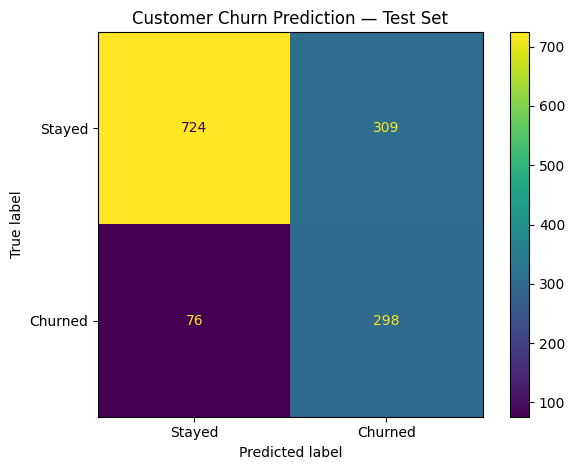

In [22]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict class labels and churn probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1-score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nDetailed classification report:")
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Stayed", "Churned"]
)
plt.title("Customer Churn Prediction — Test Set")
plt.tight_layout()
plt.show()


PART 5: Improving the model with Random Forest

Training Random Forest

In [24]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer

rf_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
)

rf_model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


Comparing both models

In [25]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

def evaluate_model(name, fitted_model):
    predictions = fitted_model.predict(X_test)
    probabilities = fitted_model.predict_proba(X_test)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    }

comparison = pd.DataFrame([
    evaluate_model("Logistic Regression", model),
    evaluate_model("Random Forest", rf_model)
])

print(comparison.round(3).to_string(index=False))


              Model  Accuracy  Precision  Recall    F1  ROC-AUC
Logistic Regression     0.726      0.491   0.797 0.608    0.835
      Random Forest     0.768      0.547   0.746 0.631    0.837


Finding the most important predictors

Top 10 predictors:
tenure                                 0.1788
TotalCharges                           0.1487
MonthlyCharges                         0.1061
Contract_Two year                      0.0985
InternetService_Fiber optic            0.0652
PaymentMethod_Electronic check         0.0504
Contract_One year                      0.0423
OnlineSecurity_Yes                     0.0369
TechSupport_Yes                        0.0217
StreamingMovies_No internet service    0.0185
dtype: float64


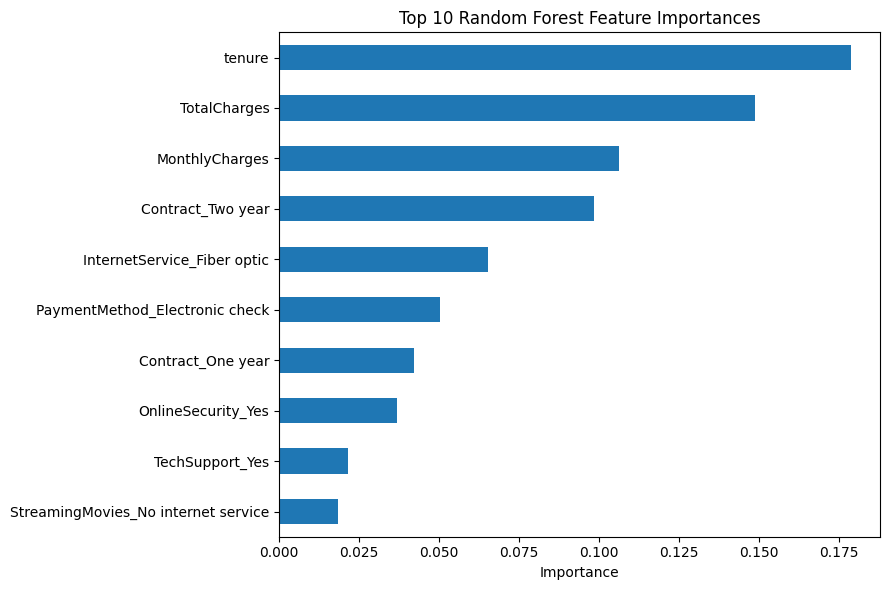

In [26]:

import pandas as pd
import matplotlib.pyplot as plt

rf = rf_model.named_steps["randomforestclassifier"]

importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 10 predictors:")
print(importance.head(10).round(4))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


Saving the results

In [27]:
importance.head(10).rename("importance").to_csv(
    "top_churn_predictors.csv",
    header=True
)

print("Saved top_churn_predictors.csv")

Saved top_churn_predictors.csv


In [36]:
from google.colab import files

files.download("top_churn_predictors.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Creating customer churn-risk scores

In [28]:
# Predict churn probabilities for the test customers
churn_probabilities = model.predict_proba(X_test)[:, 1]

# Build a customer-level results table
risk_results = pd.DataFrame({
    "Actual_Churn": y_test,
    "Churn_Risk_Score": churn_probabilities
}, index=y_test.index)

# Assign risk groups
risk_results["Risk_Level"] = pd.cut(
    risk_results["Churn_Risk_Score"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Display highest-risk customers
print(risk_results.sort_values(
    "Churn_Risk_Score", ascending=False
).head(10).round(3).to_string())

print("\nRisk group counts:")
print(risk_results["Risk_Level"].value_counts())

      Actual_Churn  Churn_Risk_Score Risk_Level
3159             0             0.934       High
3380             1             0.934       High
2631             1             0.925       High
4585             1             0.922       High
582              1             0.918       High
2797             1             0.917       High
933              1             0.917       High
3727             1             0.917       High
5213             0             0.911       High
6240             1             0.910       High

Risk group counts:
Risk_Level
Low       570
High      493
Medium    344
Name: count, dtype: int64


PART 6: Creating a retention dashboard

Risk segment summary:
Risk_Level  Customers  Actual_Churn_Rate  Average_Risk_Score
       Low        570              0.047               0.099
    Medium        344              0.230               0.450
      High        493              0.544               0.773


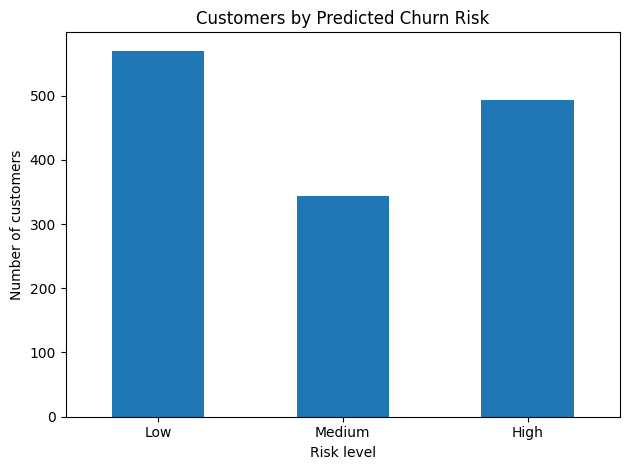

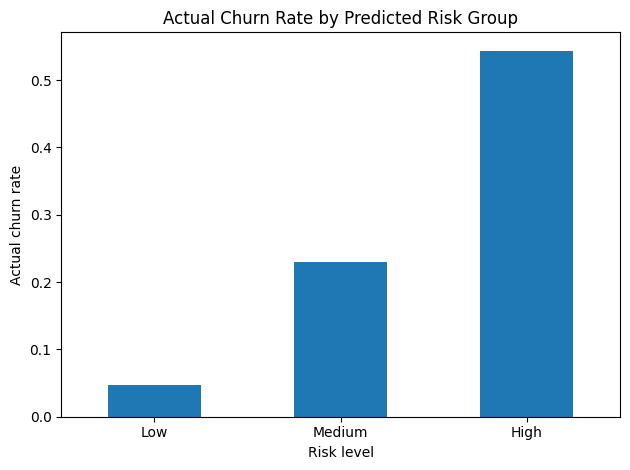

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

# Add actual outcomes to the risk summary
risk_summary = risk_results.groupby(
    "Risk_Level", observed=False
).agg(
    Customers=("Actual_Churn", "size"),
    Actual_Churn_Rate=("Actual_Churn", "mean"),
    Average_Risk_Score=("Churn_Risk_Score", "mean")
).reset_index()

print("Risk segment summary:")
print(risk_summary.round(3).to_string(index=False))

# Chart 1: number of customers in each risk group
risk_results["Risk_Level"].value_counts().reindex(
    ["Low", "Medium", "High"]
).plot(kind="bar", title="Customers by Predicted Churn Risk")

plt.xlabel("Risk level")
plt.ylabel("Number of customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Chart 2: actual churn rate in each risk group
risk_summary.plot(
    x="Risk_Level",
    y="Actual_Churn_Rate",
    kind="bar",
    legend=False,
    title="Actual Churn Rate by Predicted Risk Group"
)

plt.xlabel("Risk level")
plt.ylabel("Actual churn rate")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

PART 7: Business Recommendations

Building a business insights table

In [30]:
import pandas as pd

business_insights = pd.DataFrame([
    {
        "Finding": "High-risk customers",
        "Evidence": "54.4% actual churn rate",
        "Business_Recommendation":
            "Prioritize these customers for retention outreach"
    },
    {
        "Finding": "Low-risk customers",
        "Evidence": "4.7% actual churn rate",
        "Business_Recommendation":
            "Use lower-cost, routine engagement"
    },
    {
        "Finding": "Customer tenure",
        "Evidence": "Top Random Forest predictor",
        "Business_Recommendation":
            "Investigate onboarding and early-life churn"
    },
    {
        "Finding": "Contract type",
        "Evidence": "Important model predictor",
        "Business_Recommendation":
            "Review contract options and renewal experience"
    },
    {
        "Finding": "Monthly charges",
        "Evidence": "Important model predictor",
        "Business_Recommendation":
            "Investigate price concerns and perceived value"
    },
    {
        "Finding": "Payment method",
        "Evidence": "Electronic check appears among top predictors",
        "Business_Recommendation":
            "Review payment friction and billing communication"
    }
])

display(business_insights)

,Finding,Evidence,Business_Recommendation
0,High-risk customers,54.4% actual churn rate,Prioritize these customers for retention outreach
1,Low-risk customers,4.7% actual churn rate,"Use lower-cost, routine engagement"
2,Customer tenure,Top Random Forest predictor,Investigate onboarding and early-life churn
3,Contract type,Important model predictor,Review contract options and renewal experience
4,Monthly charges,Important model predictor,Investigate price concerns and perceived value
5,Payment method,Electronic check appears among top predictors,Review payment friction and billing communication


Estimating the potential retention opportunity

In [31]:
high_risk_customers = 493
high_risk_churn_rate = 0.544

# Illustrative assumptions, not measured campaign results
retention_scenarios = pd.DataFrame({
    "Assumed_Reduction_in_Churn": [0.05, 0.10, 0.15, 0.20]
})

retention_scenarios["Potential_Churns_Averted"] = (
    high_risk_customers
    * high_risk_churn_rate
    * retention_scenarios["Assumed_Reduction_in_Churn"]
).round(1)

retention_scenarios["Assumed_Reduction_in_Churn"] = (
    retention_scenarios["Assumed_Reduction_in_Churn"] * 100
).astype(str) + "%"

display(retention_scenarios)

,Assumed_Reduction_in_Churn,Potential_Churns_Averted
0,5.0%,13.4
1,10.0%,26.8
2,15.0%,40.2
3,20.0%,53.6


# Business Recommendations

## 1. Prioritize high-risk customers

The high-risk segment had an actual churn rate of 54.4%, compared with 23.0% for medium-risk customers and 4.7% for low-risk customers in the test sample. A retention team could use these scores to prioritize proactive outreach, account reviews, or tailored service support.

## 2. Improve early customer engagement

Customer tenure was the most important feature in the Random Forest model. The business should investigate onboarding quality, early customer support, and customer satisfaction during the initial months of service.

## 3. Review contract and pricing experiences

Contract type and monthly charges were among the model's leading predictors. Analyze churn by contract type and charging patterns, then test whether clearer contract options, billing communication, or suitable service bundles improve retention.

## 4. Investigate payment and support experiences

Payment method, online security, and technical support also contributed to the model's predictions. Review customer feedback and service interactions to identify possible payment friction or unmet support needs.

## 5. Measure retention outcomes

Pilot targeted interventions and track churn rate, retention rate, campaign response, cost per retained customer, and customer lifetime value where reliable data is available. Compare results against an appropriate control group before concluding that an intervention reduces churn.

## Limitations

The model identifies predictive relationships, not causal effects. Risk thresholds are illustrative, and the scenario estimates are not observed campaign outcomes. Validate model performance and business value on new data before operational deployment.

Saving business insights

In [32]:
business_insights.to_csv(
    "telecom_churn_business_recommendations.csv",
    index=False
)

print("Business recommendations saved successfully.")

Business recommendations saved successfully.


In [34]:
from google.colab import files

files.download("telecom_churn_business_recommendations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>